# Zoning Upside — Data Walkthrough (Phases 1 & 2)

**Goal:** find Hoboken properties where zoning allows more floors or units than exist today.

To answer that we need two halves for every property:

| Half | Question | Where it comes from |
|---|---|---|
| **Existing** | How many floors / apartments / how much land is there today? | City tax records + map shapes (Phase 1) |
| **Allowed** | What does zoning permit on this lot? | Zoning Guide text, read by an AI, checked by code, approved by a human (Phase 2) |

This notebook walks through every step using the data saved on disk. It does **not** download anything.

> *Estimate based on public zoning text; verify with the Hoboken Zoning Office.*

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from pipeline import config
from pipeline.parsers import parse_bldg_desc, parse_lot_desc

pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)
RAW = sorted((ROOT / "data/raw").iterdir())[-1]          # newest dated download folder
print("Raw data folder:", RAW.relative_to(ROOT))

Raw data folder: data/raw/2026-11-23


## 1. What we downloaded

Seven public map layers from the City's ArcGIS services. Downloaded once, at most 1 request per second, saved with a date stamp, never re-downloaded unless we run `--refresh`.

In [2]:
layers = {
    "parcels":            "Tax records, one per lot / condo unit",
    "zoning":             "Zoning districts",
    "rehab_redev":        "Redevelopment & rehabilitation areas",
    "zoning_in_progress": "Areas where rules are being changed",
    "redev_agreement":    "Developer agreements with the City",
    "historic":           "Historic districts",
    "flood":              "FEMA flood zones",
}
raw = {k: gpd.read_file(RAW / f"{k}.geojson") for k in layers}
pd.DataFrame([{"layer": k, "what it is": v, "rows": len(raw[k]), "fields": len(raw[k].columns) - 1}
              for k, v in layers.items()])

,layer,what it is,rows,fields
0,parcels,"Tax records, one per lot / condo unit",19527,18
1,zoning,Zoning districts,23,11
2,rehab_redev,Redevelopment & rehabilitation areas,13,11
3,zoning_in_progress,Areas where rules are being changed,6,10
4,redev_agreement,Developer agreements with the City,18,15
5,historic,Historic districts,764,8
6,flood,FEMA flood zones,14,14


### 1a. Tax records (parcels) — the most important layer

We request **only the 18 fields we need**. Owner name and mailing address fields are never requested, and the code refuses any response that contains them.

In [3]:
p = raw["parcels"]
print("Fields we have:", [c for c in p.columns if c != "geometry"])
print("Forbidden fields present:", [c for c in config.FORBIDDEN_FIELDS if c in p.columns] or "none ✅")
p.drop(columns="geometry").sample(8, random_state=1)

Fields we have: ['OBJECTID', 'Parcel_BLOCK', 'Parcel_LOT', 'Parcel_QUAL', 'M4_Location', 'M4_Class', 'M4_Land_Value', 'M4_Impr_Value', 'M4_Net_Value', 'M4_Sale_Date', 'M4_Sale_Price', 'M4_Bldg_Desc', 'M4_Lot_Desc', 'M4_Additional_Lots', 'M4_Zone', 'M4_Year_Built', 'M4_Sf_Area', 'M4_PAMSPIN']
Forbidden fields present: none ✅


,OBJECTID,Parcel_BLOCK,Parcel_LOT,Parcel_QUAL,M4_Location,M4_Class,M4_Land_Value,M4_Impr_Value,M4_Net_Value,M4_Sale_Date,M4_Sale_Price,M4_Bldg_Desc,M4_Lot_Desc,M4_Additional_Lots,M4_Zone,M4_Year_Built,M4_Sf_Area,M4_PAMSPIN
1892,4562118,176,7.01,C03-D,99 PARK AVE,2,211700,433800,645500,08/02/02,488000,2BR,.0588-1367 SF,,C-3,1998,1367,0905_176_7.01_C03-D
9021,4569247,168,34,C0002,606 PARK AVE,2,216700,234100,450800,04/10/01,370000,2BRM-DK,.2520-1126 SF,,R-1,1901,1124,0905_168_34_C0002
9947,4570173,84,14,C00G3,734 ADAMS ST,2,15000,20000,35000,07/07/21,425888,GARAGE,.015-171 SF,,R-2,1910,0,0905_84_14_C00G3
2780,4563006,36,1,C003H,650 SECOND ST,2,133000,268200,401200,06/28/18,557500,1BR-PS#15,.0149-885 SF,,R-3,2007,885,0905_36_1_C003H
11938,4572164,219,10.03,,823 WASHINGTON STREET,15F,0,0,0,00/00/00,0,COMMON ELEMENT,,,R-1,,0,0905_219_10.03
19496,4579722,231.03,3,C2501,225 RIVER/220 SINATRA DR,15F,0,1733000,1733000,00/00/00,0,2BR-1900SF,.0751,,RPA,2009,0,0905_231.03_3_C2501
15037,4575263,250,6,,1221 GARDEN ST,2,640000,945000,1585000,05/25/23,1,3B-1U-X-BA,16 X 100,,R-1,1892,2496,0905_250_6
18912,4579138,262.03,1,C1212,2 CONSTITUTION COURT,2,161000,327800,488800,10/25/24,830000,1BR,.4159-802 SF,,I-1W,1999,802,0905_262.03_1_C1212


### 1b. Other layers — fields at a glance

In [4]:
for k in list(layers)[1:]:
    print(f"{k:20s}", [c for c in raw[k].columns if c != "geometry"])

zoning               ['FID', 'OBJECTID', 'Zone_', 'CommZone', 'Rehab_Area', 'Shape_Leng', 'Hyperlink', 'Hyperlink2', 'Guide', 'Shape__Area', 'Shape__Length']
rehab_redev          ['FID', 'OBJECTID', 'Zone_', 'CommZone', 'Rehab_Area', 'Shape_Leng', 'Hyperlink', 'RehabRedev', 'OverlaySup', 'Shape__Area', 'Shape__Length']
zoning_in_progress   ['FID', 'OBJECTID', 'Zone_', 'CommZone', 'Rehab_Area', 'Shape_Leng', 'Hyperlink', 'Hyperlink2', 'Shape__Area', 'Shape__Length']
redev_agreement      ['FID', 'Id', 'Agreement', 'PrjctName', 'Block', 'Lot', 'AddlLots', 'F1stAmend', 'F2ndAmend', 'F3rdAmend', 'F4thAmend', 'F5thAmend', 'Note', 'Shape__Area', 'Shape__Length']
historic             ['FID', 'BLOCK', 'LOT', 'Muni', 'Historic_D', 'Hyperlink', 'Shape__Area', 'Shape__Length']
flood                ['FID', 'FID_Adv_HU', 'OBJECTID', 'ABFE_1Pct', 'ABFE_0_2Pc', 'ZONE', 'STATE', 'COUNTY', 'SHAPE_Leng', 'FID_Hudson', 'MUN', 'ABFE_FT', 'Shape__Area', 'Shape__Length']


## 2. Reading the assessor's shorthand

The tax office writes buildings and lot sizes as short codes. Our parsers turn them into numbers.
If a code can't be read it is left **empty and flagged** — never guessed.

In [5]:
examples = ["3F-2U-G", "4B-3U-1C", "3B-2U/3B-2U", "3,4B-2U", "4 1/2B-10U", "VACANT LAND", "2BR-DECK", "PARKING LOT", "WAREHOUSE"]
rows = []
for e in examples:
    b = parse_bldg_desc(e)
    rows.append({"raw": e, "status": b.parse_status, "stories": b.existing_stories, "material": b.material,
                 "units": b.existing_units, "commercial": b.commercial_units, "buildings": b.building_count, "tags": b.tags})
pd.DataFrame(rows)

,raw,status,stories,material,units,commercial,buildings,tags
0,3F-2U-G,ok,3.0,Frame,2.0,NaN,1.0,[G]
1,4B-3U-1C,ok,4.0,Brick,3.0,1.0,1.0,[]
2,3B-2U/3B-2U,ok,3.0,Brick,4.0,NaN,2.0,[]
3,"3,4B-2U",ok,4.0,Brick,2.0,NaN,1.0,[]
4,4 1/2B-10U,ok,4.5,Brick,10.0,NaN,1.0,[]
5,VACANT LAND,non_residential,0.0,NaN,0.0,NaN,0.0,[VACANT LAND]
6,2BR-DECK,condo_unit,NaN,NaN,NaN,NaN,NaN,[]
7,PARKING LOT,non_residential,0.0,NaN,0.0,NaN,0.0,[PARKING LOT]
8,WAREHOUSE,unparsed,NaN,NaN,NaN,NaN,NaN,[]


In [6]:
examples = ["25 X 100", "25X75CORNER", "22 X 50 IRREG.", "35000 SQ FT", "1.862 ACRES", "25X100&25X50", "AVG 20 X 100"]
pd.DataFrame([{"raw": e, **{k: v for k, v in vars(parse_lot_desc(e)).items()}} for e in examples])

,raw,parse_status,lot_width_ft,lot_depth_ft,lot_area_sqft,irregular,average,corner,multi_part,area_source
0,25 X 100,ok,25.0,100.0,2500.0,False,False,False,False,dims
1,25X75CORNER,ok,25.0,75.0,1875.0,False,False,True,False,dims
2,22 X 50 IRREG.,ok,22.0,50.0,1100.0,True,False,False,False,dims
3,35000 SQ FT,ok,NaN,NaN,35000.0,False,False,False,False,stated_sqft
4,1.862 ACRES,ok,NaN,NaN,81109.0,False,False,False,False,stated_acres
5,25X100&25X50,ok,25.0,100.0,3750.0,False,False,False,True,dims
6,AVG 20 X 100,ok,20.0,100.0,2000.0,False,True,False,False,dims


## 3. From 19,527 records to 4,001 "sites"

A **site** = one property an investor could buy. Three problems had to be fixed:

1. **Condo units** — every apartment in a condo building is its own tax record. We group them into one *condo building* and keep them out of the ranking (one unit owner can't redevelop the building).
2. **Combined properties** — one big property is often listed on many lots with the *same* record copied onto each. We merge them so the land isn't counted 18 times.
3. **Additional Lots** field — some records list the other lots they include; those are folded into the lead lot.

In [7]:
rec = pd.read_parquet("data/processed/records.parquet")
sites = gpd.read_parquet("data/processed/sites.parquet")
print(f"Tax records:              {len(rec):>6,}")
print(f"  of which condo records: {rec.is_condo_record.sum():>6,}")
print(f"Sites after grouping:     {len(sites):>6,}")
print(f"  condo buildings:        {sites.is_condo_building.sum():>6,}")
print(f"  normal sites:           {(~sites.is_condo_building).sum():>6,}")

Tax records:              19,527
  of which condo records: 15,929
Sites after grouping:      4,001
  condo buildings:         1,166
  normal sites:            2,835


**Example — condo grouping:** the biggest condo buildings, each now a single site.

In [8]:
sites[sites.is_condo_building].nlargest(5, "condo_unit_count")[["block", "lot", "location", "condo_unit_count", "record_count", "net_value"]]

,block,lot,location,condo_unit_count,record_count,net_value
3937,261.03,1,1125 MAXWELL LANE,754,755,386286500.0
3952,261.01,1,1100 MAXWELL LANE,422,423,185767800.0
3741,269.03,1,1400 HUDSON ST,359,360,188671500.0
3938,261.04,1,1025 MAXWELL LANE,339,340,162151700.0
351,25,1,700 FIRST STREET,329,330,174266300.0


**Example — duplicate-record merge:** Block 10's big property was copied onto 19 lots. Now it's one site, and the tax-record area matches the map shape.

In [9]:
s = sites[sites.merged_lots.map(len) > 0].copy()
s["lots_merged"] = s.merged_lots.map(len)
s.nlargest(6, "lots_merged")[["block", "lot", "lots_merged", "location", "lot_desc", "lot_area_sqft", "geom_area_sqft"]]

,block,lot,lots_merged,location,lot_desc,lot_area_sqft,geom_area_sqft
3641,129,1,31,1500 ADAMS ST,400X200,80000.0,80000.0
3806,131,1,31,1500 CLINTON ST,400X200,80000.0,80000.0
3804,130,1,27,1501 ADAMS ST,"70,000 SF.",70000.0,70000.0
13,10,8,19,111 PATERSON/ 85 MARSHALL,61229 SQ FT,61229.0,61253.7
3269,103,7,19,1113 MADISON ST,"50,000 SQ SF",50000.0,50000.0
1264,51,1,18,300-20 GRAND ST/301ADAMS,"47,500 SF",47500.0,47500.0


## 4. Quality checks

**Lot area check:** we compare the area written in the tax record with the area measured from the map shape (in NJ State Plane feet).
A ratio near 1.0 means they agree. Outside 0.67–1.5 the site is flagged.

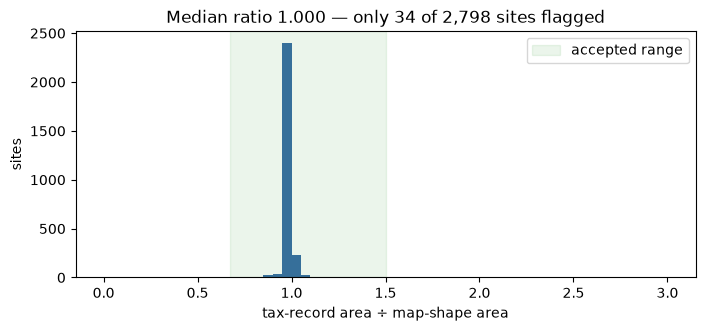

In [10]:
ns = sites[~sites.is_condo_building]
ratio = ns.lot_area_ratio.dropna().clip(0, 3)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(ratio, bins=60, color="#3b6ea8")
ax.axvspan(0.67, 1.5, color="green", alpha=0.08, label="accepted range")
ax.set_xlabel("tax-record area ÷ map-shape area"); ax.set_ylabel("sites"); ax.legend()
ax.set_title(f"Median ratio {ratio.median():.3f} — only {ns.area_mismatch.sum()} of {ratio.size:,} sites flagged")
plt.show()

In [11]:
pd.DataFrame({
    "building description": ns.parse_status.value_counts(),
    "share": ns.parse_status.value_counts(normalize=True).map("{:.1%}".format),
})

,building description,share
parse_status,,
ok,2300,81.1%
non_residential,370,13.1%
unparsed,165,5.8%


## 5. Attaching zone and warning flags

For each site we overlay the maps:
- **Zone** = the zoning district covering the largest part of the site (checked against the tax office's zone).
- **Warning flags** = a constraint layer must cover **at least 10%** of the site (ignores slivers along shared edges).

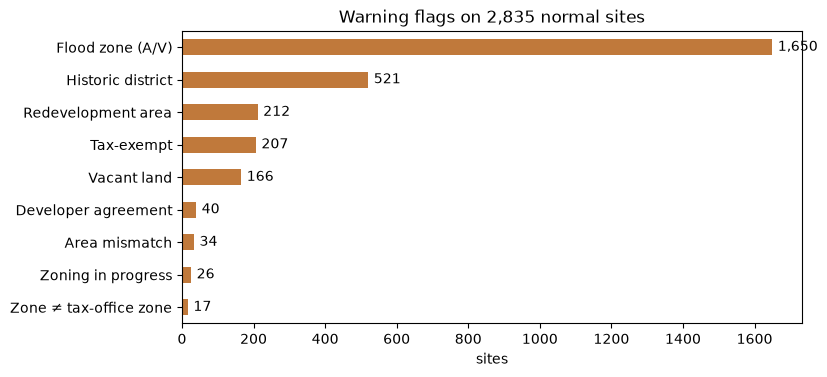

In [12]:
flags = {
    "Flood zone (A/V)": "in_flood_hazard_area", "Historic district": "in_historic_district",
    "Redevelopment area": "in_redev_area", "Tax-exempt": "is_exempt", "Vacant land": "is_vacant_land",
    "Developer agreement": "has_redev_agreement", "Zoning in progress": "in_zoning_in_progress",
    "Zone ≠ tax-office zone": "zone_mismatch", "Area mismatch": "area_mismatch",
}
counts = pd.Series({k: int(ns[v].sum()) for k, v in flags.items()}).sort_values()
ax = counts.plot.barh(figsize=(8, 3.8), color="#c0793b")
ax.set_title(f"Warning flags on {len(ns):,} normal sites"); ax.set_xlabel("sites")
for i, v in enumerate(counts): ax.text(v + 15, i, f"{v:,}", va="center")
plt.show()

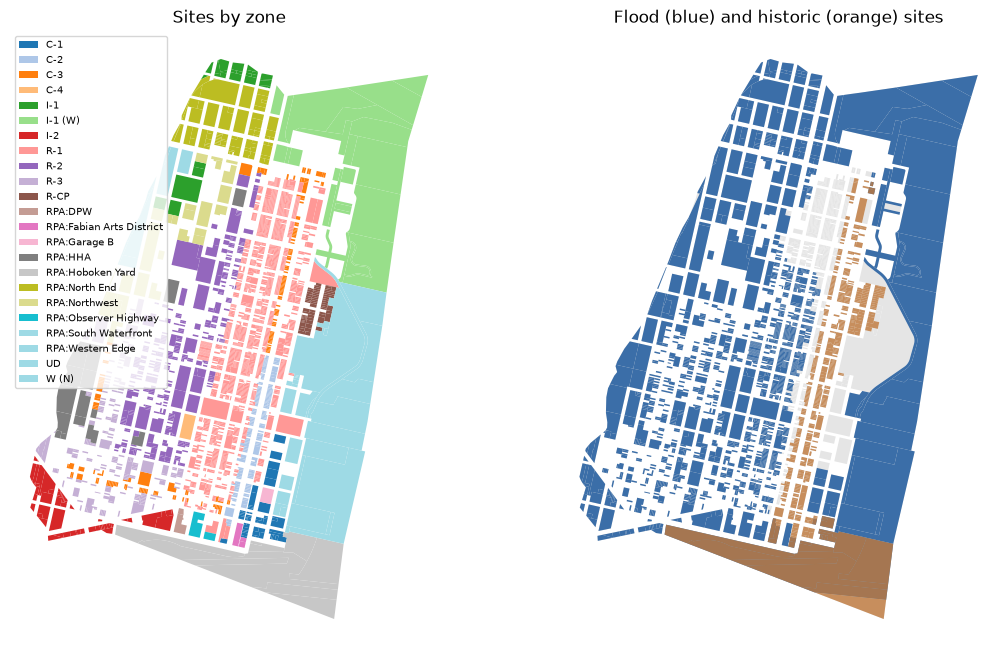

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 8))
ns.plot(ax=axes[0], column="zone_key", categorical=True, legend=True, cmap="tab20", linewidth=0,
        legend_kwds={"loc": "upper left", "fontsize": 7})
axes[0].set_title("Sites by zone")
ns.plot(ax=axes[1], color="#e5e5e5", linewidth=0)
ns[ns.in_flood_hazard_area].plot(ax=axes[1], color="#3b6ea8", linewidth=0, label="flood")
ns[ns.in_historic_district].plot(ax=axes[1], color="#c0793b", linewidth=0, alpha=0.8)
axes[1].set_title("Flood (blue) and historic (orange) sites")
for a in axes: a.set_axis_off()
plt.show()

## 6. Zoning rules (Phase 2)

An AI (Groq, free tier) read the City's Zoning Guide pages and pulled out each rule **with the exact sentence as proof**.
Code then checked every value: the quote must exist in the source, and the number must appear in the quote.
Finally each zone was reviewed and **approved by a person** on the review page.

Only approved values will be used in calculations.

In [14]:
approved = json.load(open("data/rules/hoboken_rules.json"))["zones"]
rows = []
for zk, z in approved.items():
    for d in z["districts"]:
        f, ds = d["fields"], d["density_structured"] or {}
        v = lambda k: (f.get(k) or {}).get("value")
        rows.append({"zone": zk, "sub-district": d["name"] or "", "max height ft": v("max_height_ft"),
                     "max stories": v("max_stories"), "measured from": v("height_measured_from"),
                     "max coverage %": v("max_lot_coverage_pct"), "min lot sq ft": v("min_lot_area_sqft"),
                     "density rule": ds.get("type"), "sq ft per unit": ds.get("site_area_per_unit_sqft"),
                     "approved": z["approved_at"]})
rules = pd.DataFrame(rows); rules

,zone,sub-district,max height ft,max stories,measured from,max coverage %,min lot sq ft,density rule,sq ft per unit,approved
0,C-1,,60,5.0,grade,80,5000,none,NaN,2026-11-24
1,C-2,,52,NaN,grade,60,2000,site_area_per_unit,330.0,2026-11-24
2,C-2,Court Street,52,NaN,grade,60,2000,formula,NaN,2026-11-24
3,C-3,,52,5.0,grade,60,2000,site_area_per_unit,500.0,2026-11-24
4,R-1,,40,3.0,design_flood_elevation,60,2000,site_area_per_unit,660.0,2026-11-24
5,R-2,,40,NaN,design_flood_elevation,60,2000,site_area_per_unit,660.0,2026-11-24
6,R-3,,40,NaN,design_flood_elevation,60,2500,site_area_per_unit,660.0,2026-11-24
7,R-CP,,40,3.5,grade,50,3000,site_area_per_unit,2000.0,2026-11-24


**Every number carries its proof.** Example — R-1 height and density:

In [15]:
r1 = approved["R-1"]["districts"][0]
for k in ["max_height_ft", "max_stories"]:
    e = r1["fields"][k]; print(f"{k} = {e['value']}\n   “{e['quote']}”\n   {e['source_url']}\n")
d = r1["density_structured"]; print(f"density: {d['site_area_per_unit_sqft']} sq ft per unit\n   “{d['quote']}”")

max_height_ft = 40
   “maximum residential building height of 40 feet above Design Flood Elevation (DFE)”
   https://city-of-hoboken-zoning-guide-cityofhoboken.hub.arcgis.com/pages/r-1-district

max_stories = 3
   “or three stories”
   https://city-of-hoboken-zoning-guide-cityofhoboken.hub.arcgis.com/pages/r-1-district

density: 660 sq ft per unit
   “The number of residential units ... determined by dividing the site area by 660 and rounding to the closest whole number.”


## 7. Demo scope

For the demo we use **only the 7 zones with approved rules** (R-1, R-2, R-3, R-CP, C-1, C-2, C-3).
Sites in other zones (industrial, redevelopment plans, etc.) stay in the data but are marked *"rules not loaded"* and are not scored.

Normal sites in approved zones: 2,559 of 2,835 (90%)


sites
scope            zone_key                       
in demo          C-1                          53
                 C-2                         161
                 C-3                         164
                 R-1                        1577
                 R-2                         347
                 R-3                         193
                 R-CP                         64
rules not loaded C-4                           1
                 I-1                          26
                 I-1 (W)                      23
                 I-2                          54
                 RPA:DPW                       2
                 RPA:Fabian Arts District      3
                 RPA:Garage B                  1
                 RPA:HHA                      16
                 RPA:Hoboken Yard              9
                 RPA:North End                71
                 RPA:Northwest                30
                 RPA:Observer Highway          2
                 RPA:South Waterfront         12
                 RPA:Western Edge             10
                 UD                           12
                 W (N)                         4

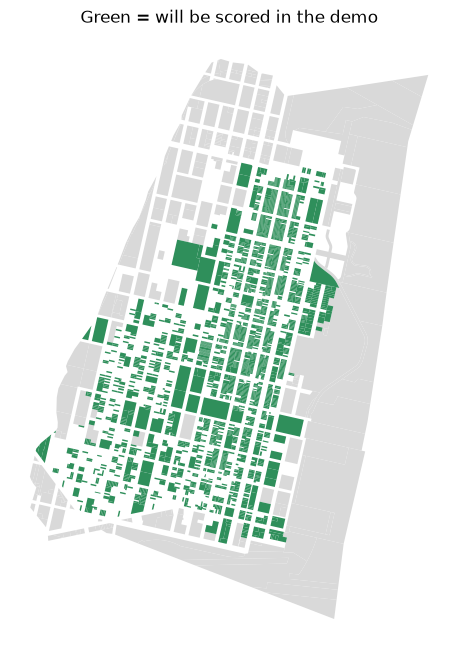

In [16]:
in_scope = ns.zone_key.isin(approved)
print(f"Normal sites in approved zones: {in_scope.sum():,} of {len(ns):,} ({in_scope.mean():.0%})")
scope = ns.assign(scope=in_scope.map({True: "in demo", False: "rules not loaded"}))
display(scope.groupby(["scope", "zone_key"]).size().rename("sites").to_frame())

fig, ax = plt.subplots(figsize=(6, 8))
scope[~in_scope].plot(ax=ax, color="#d9d9d9", linewidth=0)
scope[in_scope].plot(ax=ax, color="#2f8f5b", linewidth=0)
ax.set_title("Green = will be scored in the demo"); ax.set_axis_off(); plt.show()

## 8. Summary

| Step | Result |
|---|---|
| Downloaded | 7 public layers, 19,527 tax records — no owner data |
| Cleaned | 4,001 sites (2,835 normal + 1,166 condo buildings) |
| Parsed | floors & units known for 2,421 sites; lot size for 2,798 |
| Flagged | flood, historic, redevelopment, exempt, vacant, mismatches |
| Rules | 7 zones extracted with proof, checked by code, approved by a person |

**Next (Phase 3):** for each in-scope site, compute *allowed − existing* floors and units, then score and rank.